# Predicción de la temperatura superficial (LST) con búsqueda paralela de hiperparámetros

**Objetivo:** predecir la temperatura superficial terrestre (LST, °C) a partir de NDVI, altitud, ubicación y número de banda temporal.

**Datos:** archivos raster GeoTIFF `LST_mensual.tif`, `NDVI_mensual.tif` y `ALTITUD.tif`. LST y NDVI deben tener el mismo número de bandas y dimensiones; altitud tiene una sola banda.

**Modelos:** KNN, Random Forest y SVR.

**Paralelismo:** cada combinación de hiperparámetros es una tarea independiente. Se reparten entre procesos con `multiprocessing`, sin `joblib` ni `n_jobs`.

**Importante:** los archivos raster no aportan por sí solos fechas/años verificables en este flujo. Por eso, la partición se hará al azar y no se afirmará que el conjunto de prueba representa un año específico.

**Cómo correrlo:** coloca `paralelo.py` en la misma carpeta que este notebook, revisa las rutas de los tres TIFF en la celda 2 y ejecuta todas las celdas en orden.

In [2]:
%pip install rasterio numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
# 1 hilo por proceso en numpy/scikit-learn: el único paralelismo es el nuestro
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"

import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.transform import xy
import paralelo as par

# ---------------- Parámetros ----------------
RUTA_LST = r"C:\Users\brand\Desktop\Proyecto Computo paralelo\2do parcial\LST_mensual.tif"
RUTA_NDVI = r"C:\Users\brand\Desktop\Proyecto Computo paralelo\2do parcial\NDVI_mensual.tif"
RUTA_ALTITUD = r"C:\Users\brand\Desktop\Proyecto Computo paralelo\2do parcial\ALTITUD.tif"
N_MAX_ENTRENAMIENTO = int(os.environ.get("N_MAX", 40000))
SEMILLA = 42
NUCLEOS = mp.cpu_count()
LISTA_PROCESOS = [p for p in [1, 2, 4, 8, 16] if p <= NUCLEOS]

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

# Colores fijos por modelo (siempre el mismo color para el mismo modelo)
COLORES = {"KNN": "#2a78d6", "RF": "#eb6834", "SVR": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print("Núcleos disponibles:", NUCLEOS)
print("Se medirá con procesos:", LISTA_PROCESOS)

Núcleos disponibles: 16
Se medirá con procesos: [1, 2, 4, 8, 16]


## 1. Carga y limpieza de los datos

In [4]:
# Cargar una muestra de los raster para que el notebook no necesite guardar millones de filas en memoria.
# Se toma una cantidad similar de puntos de cada banda temporal.
filas = []

with rasterio.open(RUTA_LST) as src_lst, rasterio.open(RUTA_NDVI) as src_ndvi, rasterio.open(RUTA_ALTITUD) as src_alt:
    if (src_lst.width, src_lst.height, src_lst.crs) != (src_ndvi.width, src_ndvi.height, src_ndvi.crs):
        raise ValueError("LST y NDVI deben tener las mismas dimensiones y el mismo CRS.")
    if (src_lst.width, src_lst.height, src_lst.crs) != (src_alt.width, src_alt.height, src_alt.crs):
        raise ValueError("LST y ALTITUD deben tener las mismas dimensiones y el mismo CRS.")
    if src_lst.count != src_ndvi.count:
        raise ValueError("LST y NDVI deben tener el mismo número de bandas.")

    n_bandas = src_lst.count
    por_banda = max(1, int(np.ceil(N_MAX_ENTRENAMIENTO / n_bandas)))
    altitud = src_alt.read(1, masked=True).filled(np.nan).astype("float32")
    transform = src_lst.transform

    for banda in range(1, n_bandas + 1):
        lst = src_lst.read(banda, masked=True).filled(np.nan).astype("float32")
        ndvi = src_ndvi.read(banda, masked=True).filled(np.nan).astype("float32")

        valido = (
            np.isfinite(lst) & np.isfinite(ndvi) & np.isfinite(altitud)
            & (ndvi >= -1) & (ndvi <= 1)
            & (lst > -20) & (lst < 75)
        )
        rr, cc = np.where(valido)
        if len(rr) == 0:
            continue

        rng = np.random.default_rng(SEMILLA + banda)
        n = min(por_banda, len(rr))
        elegir = rng.choice(len(rr), size=n, replace=False)
        rr, cc = rr[elegir], cc[elegir]
        xs, ys = xy(transform, rr, cc)

        filas.append(pd.DataFrame({
            "LST": lst[rr, cc],
            "NDVI": ndvi[rr, cc],
            "ALTITUD": altitud[rr, cc],
            "lon": np.asarray(xs),
            "lat": np.asarray(ys),
            "banda": banda
        }))

if not filas:
    raise ValueError("No se encontraron datos válidos. Revisa si LST está expresada en °C y si los NoData están definidos correctamente.")

df = pd.concat(filas, ignore_index=True)
df = par.limpiar(df)

print("Bandas disponibles:", n_bandas)
print("Filas de la muestra:", len(df))
print("Filas por banda:")
print(df["banda"].value_counts().sort_index())
print("\nResumen de variables:")
df[["LST", "NDVI", "ALTITUD", "lat", "lon", "banda"]].describe().round(3)

Filas: 40,080 -> 40,080 después de limpiar
Bandas disponibles: 120
Filas de la muestra: 40080
Filas por banda:
banda
1      334
2      334
3      334
4      334
5      334
      ... 
116    334
117    334
118    334
119    334
120    334
Name: count, Length: 120, dtype: int64

Resumen de variables:


,LST,NDVI,ALTITUD,lat,lon,banda
count,40080.000,40080.000,40080.000,40080.000,40080.000,40080.00
mean,28.706,0.526,1821.391,19.084,-97.841,60.50
std,6.008,0.205,769.838,0.700,0.455,34.64
min,2.875,-0.187,41.000,17.908,-98.972,1.00
25%,24.665,0.339,1278.000,18.465,-98.172,30.75
50%,28.250,0.524,1973.000,19.013,-97.840,60.50
75%,32.625,0.716,2420.000,19.588,-97.490,90.25
max,50.170,0.929,5322.000,20.854,-96.645,120.00


In [5]:
# Descripción de los datos para el documento (tabla de resultados)
desc = df[["LST", "NDVI", "ALTITUD", "lat", "lon", "banda"]].describe().T[["mean", "std", "min", "max"]]
desc.columns = ["media", "desv_est", "min", "max"]
resumen_datos = pd.DataFrame({
    "dato": ["Puntos (filas de la muestra)", "Bandas temporales representadas", "Bandas inicial y final"],
    "valor": [len(df), df["banda"].nunique(), f'{df["banda"].min()} a {df["banda"].max()}']
})
desc.round(3).to_csv("resultados/descripcion_variables.csv")
resumen_datos.to_csv("resultados/resumen_datos.csv", index=False)
display(resumen_datos)
desc.round(3)

,dato,valor
0,Puntos (filas de la muestra),40080
1,Bandas temporales representadas,120
2,Bandas inicial y final,1 a 120


,media,desv_est,min,max
LST,28.706,6.008,2.875,50.170
NDVI,0.526,0.205,-0.187,0.929
ALTITUD,1821.391,769.838,41.000,5322.000
lat,19.084,0.700,17.908,20.854
lon,-97.841,0.455,-98.972,-96.645
banda,60.500,34.640,1.000,120.000


In [6]:
# Correlación de cada variable con la temperatura
corr = df[par.COLUMNAS_X + ["LST"]].corr()["LST"].drop("LST").sort_values()
print("Correlación con LST:")
print(corr.round(3))

Correlación con LST:
NDVI      -0.617
lat       -0.218
ALTITUD   -0.211
lon       -0.173
banda     -0.016
Name: LST, dtype: float64


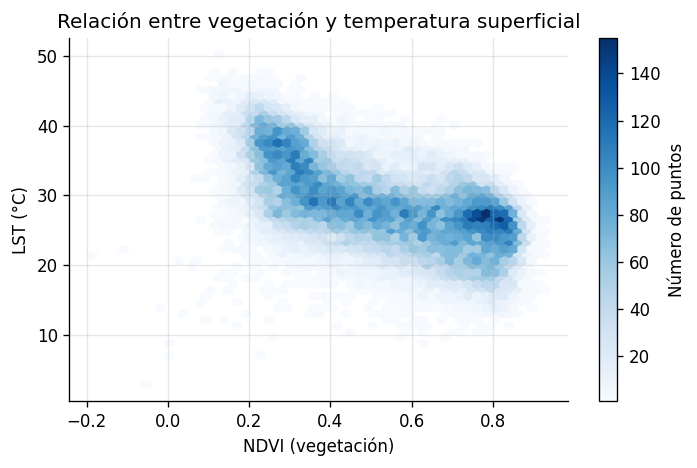

In [7]:
# Relación entre vegetación y temperatura (la idea central del proyecto)
fig, ax = plt.subplots(figsize=(6, 4))
hb = ax.hexbin(df["NDVI"], df["LST"], gridsize=50, cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax, label="Número de puntos")
ax.set_xlabel("NDVI (vegetación)")
ax.set_ylabel("LST (°C)")
ax.set_title("Relación entre vegetación y temperatura superficial")
fig.tight_layout()
fig.savefig("figuras/ndvi_vs_lst.png", dpi=200)
plt.show()

## 2. Partición de los datos

- **Entrenamiento:** se utiliza para ajustar los modelos.
- **Validación:** permite escoger los mejores hiperparámetros.
- **Prueba:** se reserva para medir el desempeño final.

Como los GeoTIFF proporcionados no incluyen una fecha/año verificable en este flujo, los registros se dividen al azar. La muestra se limita para que la búsqueda de hiperparámetros pueda ejecutarse en un equipo personal.

In [8]:
ent, val, prueba = par.particionar(df, n_max_entrenamiento=N_MAX_ENTRENAMIENTO, semilla=SEMILLA)

X_ent, y_ent = ent[par.COLUMNAS_X].to_numpy(), ent[par.COLUMNA_Y].to_numpy()
X_val, y_val = val[par.COLUMNAS_X].to_numpy(), val[par.COLUMNA_Y].to_numpy()
X_pru, y_pru = prueba[par.COLUMNAS_X].to_numpy(), prueba[par.COLUMNA_Y].to_numpy()
datos = (X_ent, y_ent, X_val, y_val)

tareas = par.lista_de_tareas()
print(f"\nTareas (combinaciones de hiperparámetros): {len(tareas)}")
for m in par.REJILLA:
    print(f"  {m}: {sum(t[0] == m for t in tareas)} combinaciones -> {par.REJILLA[m]}")

Entrenamiento: 25,652 | Validación: 6,412 | Prueba: 8,016

Tareas (combinaciones de hiperparámetros): 46
  KNN: 16 combinaciones -> {'n_neighbors': [3, 5, 10, 20], 'weights': ['uniform', 'distance'], 'p': [1, 2]}
  RF: 18 combinaciones -> {'n_estimators': [50, 100, 200], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5]}
  SVR: 12 combinaciones -> {'C': [1, 10, 100], 'epsilon': [0.1, 0.5], 'gamma': ['scale', 0.1]}


## 3. Búsqueda de hiperparámetros: secuencial y en paralelo

Se ejecuta la misma búsqueda con 1 proceso (secuencial) y con varios procesos. El reparto es **dinámico**: cada proceso toma la siguiente combinación en cuanto termina la anterior, lo que nivela la carga porque las combinaciones no tardan lo mismo (un Random Forest de 200 árboles tarda mucho más que un KNN).

In [9]:
tiempos = {}
resultados_por_p = {}
for p in LISTA_PROCESOS:
    res, t = par.busqueda(tareas, datos, procesos=p, reparto="dinamico")
    tiempos[p] = t
    resultados_por_p[p] = pd.DataFrame(res)
    print(f"{p:>2} procesos: {t:8.2f} s")

busqueda = resultados_por_p[1].sort_values("RMSE")
busqueda.to_csv("resultados/busqueda_hiperparametros.csv", index=False)

 1 procesos:   244.93 s
 2 procesos:   225.97 s
 4 procesos:   121.78 s
 8 procesos:    79.94 s
16 procesos:    75.51 s


In [10]:
# Validación: el resultado en paralelo debe ser IGUAL al secuencial (solo cambia el tiempo)
base = resultados_por_p[1].set_index(["modelo", "params"])["RMSE"]
for p, r in resultados_por_p.items():
    dif = (r.set_index(["modelo", "params"])["RMSE"] - base).abs().max()
    print(f"{p:>2} procesos: diferencia máxima de RMSE contra secuencial = {dif:.2e}")

 1 procesos: diferencia máxima de RMSE contra secuencial = 0.00e+00
 2 procesos: diferencia máxima de RMSE contra secuencial = 0.00e+00
 4 procesos: diferencia máxima de RMSE contra secuencial = 0.00e+00
 8 procesos: diferencia máxima de RMSE contra secuencial = 0.00e+00
16 procesos: diferencia máxima de RMSE contra secuencial = 0.00e+00


## 4. Métricas de desempeño paralelo

In [11]:
desempeno = par.metricas_paralelas(tiempos)
desempeno.to_csv("resultados/desempeno_paralelo.csv", index=False)
desempeno.round(3)

,procesos,tiempo_s,speedup,eficiencia,karp_flatt
0,1,244.933,1.000,1.000,NaN
1,2,225.968,1.084,0.542,0.845
2,4,121.778,2.011,0.503,0.330
3,8,79.944,3.064,0.383,0.230
4,16,75.509,3.244,0.203,0.262


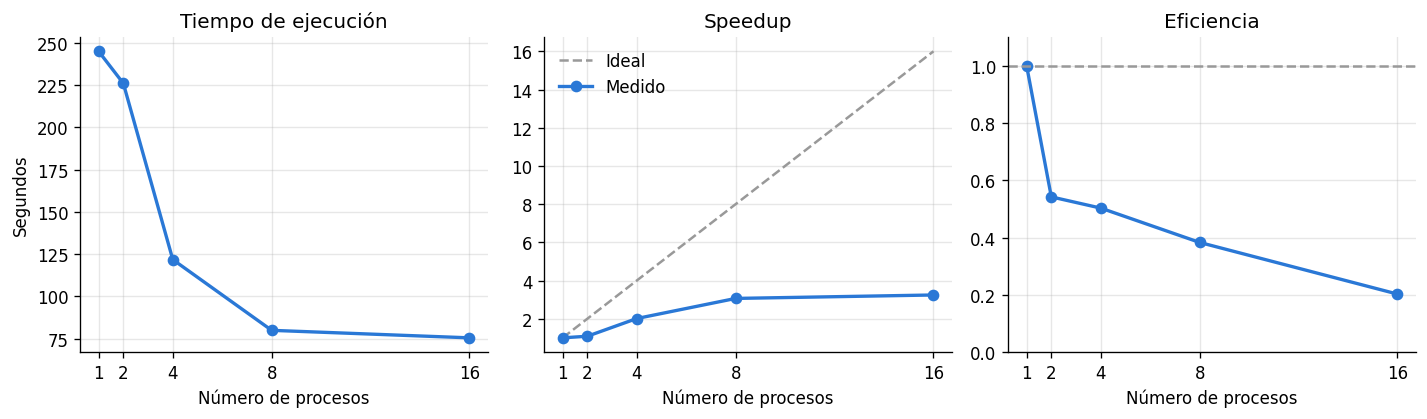

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
P = desempeno["procesos"]

axes[0].plot(P, desempeno["tiempo_s"], marker="o", color="#2a78d6", lw=2)
axes[0].set_title("Tiempo de ejecución")
axes[0].set_ylabel("Segundos")

axes[1].plot(P, P, ls="--", color="#999999", lw=1.5, label="Ideal")
axes[1].plot(P, desempeno["speedup"], marker="o", color="#2a78d6", lw=2, label="Medido")
axes[1].set_title("Speedup")
axes[1].legend(frameon=False)

axes[2].plot(P, desempeno["eficiencia"], marker="o", color="#2a78d6", lw=2)
axes[2].axhline(1, ls="--", color="#999999", lw=1.5)
axes[2].set_ylim(0, 1.1)
axes[2].set_title("Eficiencia")

for ax in axes:
    ax.set_xlabel("Número de procesos")
    ax.set_xticks(P)
fig.tight_layout()
fig.savefig("figuras/desempeno_paralelo.png", dpi=200)
plt.show()

## 5. Nivelación de cargas: reparto estático vs. dinámico

- **Estático:** las tareas se parten en bloques fijos con el algoritmo de la diapositiva 101 (`nivelar`). Todos los procesos reciben casi el mismo *número* de tareas, pero no el mismo *tiempo* de trabajo.
- **Dinámico:** cada proceso toma la siguiente tarea al terminar (`imap_unordered`).

In [13]:
p_max = max(LISTA_PROCESOS)
if p_max > 1:
    _, t_est = par.busqueda(tareas, datos, procesos=p_max, reparto="estatico")
    t_din = tiempos[p_max]
    comparacion = pd.DataFrame({
        "reparto": ["Estático (nivelar)", "Dinámico (imap_unordered)"],
        "procesos": [p_max, p_max],
        "tiempo_s": [t_est, t_din],
        "speedup": [tiempos[1] / t_est, tiempos[1] / t_din],
    })
    comparacion.to_csv("resultados/estatico_vs_dinamico.csv", index=False)
    display(comparacion.round(3))

# Cuánto tarda cada tipo de modelo (explica por qué la carga es desigual)
carga = resultados_por_p[1].groupby("modelo")["segundos"].agg(["count", "sum", "mean"]).round(2)
carga.columns = ["tareas", "segundos_totales", "segundos_por_tarea"]
carga

,reparto,procesos,tiempo_s,speedup
0,Estático (nivelar),16,123.463,1.984
1,Dinámico (imap_unordered),16,75.509,3.244


,tareas,segundos_totales,segundos_por_tarea
modelo,,,
KNN,16,2.39,0.15
RF,18,143.99,8.00
SVR,12,98.40,8.20


## 6. Mejores hiperparámetros por modelo (validación)

In [14]:
mejores = busqueda.loc[busqueda.groupby("modelo")["RMSE"].idxmin()].sort_values("RMSE")
mejores[["modelo", "params", "RMSE", "MAE", "R2", "segundos"]].round(3)

,modelo,params,RMSE,MAE,R2,segundos
32,RF,"{'n_estimators': 200, 'max_depth': None, 'min_...",2.557,1.960,0.816,18.076
10,KNN,"{'n_neighbors': 10, 'weights': 'distance', 'p'...",3.285,2.536,0.696,0.147
40,SVR,"{'C': 10, 'epsilon': 0.5, 'gamma': 'scale'}",3.619,2.791,0.631,5.232


## 7. Curvas de aprendizaje

Con los mejores hiperparámetros de cada modelo se entrena con cantidades crecientes de datos y se mide el RMSE en entrenamiento y en validación. Si las dos curvas se juntan, más datos ya no ayudan mucho; si quedan separadas, el modelo memoriza (sobreajuste). Cada punto de la curva es una tarea independiente, así que también se calcula en paralelo.

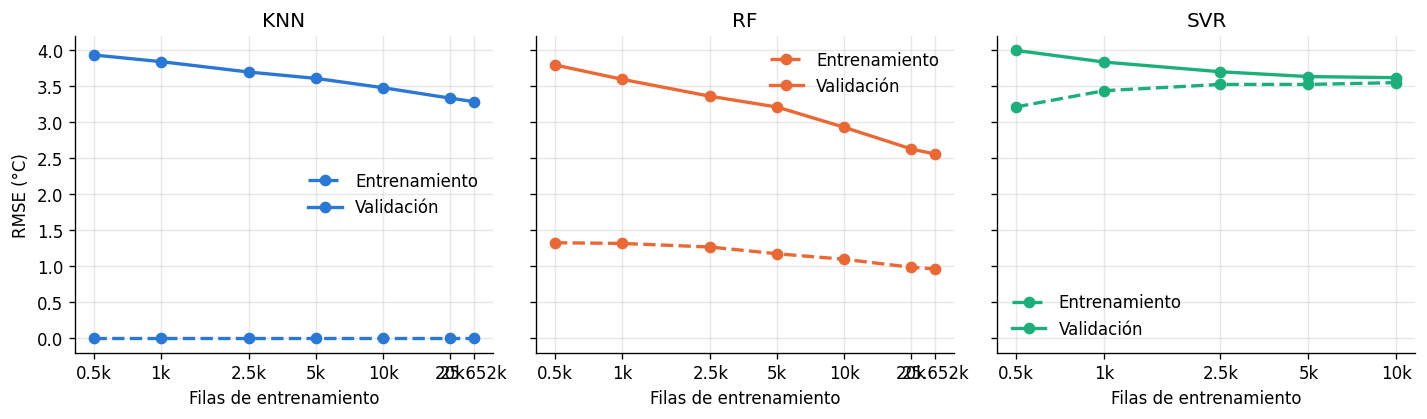

In [15]:
import ast
tamanos = [n for n in [500, 1000, 2500, 5000, 10000, 20000, 40000] if n <= len(X_ent)]
if len(X_ent) not in tamanos:
    tamanos.append(len(X_ent))
tareas_curva = []
for _, fila in mejores.iterrows():
    params = ast.literal_eval(fila["params"])
    for n in tamanos:
        if fila["modelo"] == "SVR" and n > par.N_MAX_SVR:
            continue
        tareas_curva.append((fila["modelo"], params, n))

with mp.Pool(processes=max(LISTA_PROCESOS), initializer=par.inicializar, initargs=datos) as pool:
    curvas = pd.DataFrame(pool.map(par.evaluar_curva, tareas_curva))
curvas.to_csv("resultados/curvas_aprendizaje.csv", index=False)

fig, axes = plt.subplots(1, curvas["modelo"].nunique(), figsize=(12, 3.6), sharey=True)
for ax, (nombre, c) in zip(np.atleast_1d(axes), curvas.groupby("modelo")):
    c = c.sort_values("n")
    ax.plot(c["n"], c["RMSE_entrenamiento"], marker="o", lw=2, color=COLORES[nombre], ls="--", label="Entrenamiento")
    ax.plot(c["n"], c["RMSE_validacion"], marker="o", lw=2, color=COLORES[nombre], label="Validación")
    ax.set_xscale("log")
    ax.set_xticks(c["n"])
    ax.set_xticklabels([f"{n/1000:g}k" for n in c["n"]])
    ax.minorticks_off()
    ax.set_title(nombre)
    ax.set_xlabel("Filas de entrenamiento")
    ax.legend(frameon=False)
np.atleast_1d(axes)[0].set_ylabel("RMSE (°C)")
fig.tight_layout()
fig.savefig("figuras/curvas_aprendizaje.png", dpi=200)
plt.show()

## 8. Evaluación final en el conjunto de prueba

In [16]:
import ast
filas, predicciones, modelos_finales = [], {}, {}
for _, fila in mejores.iterrows():
    params = ast.literal_eval(fila["params"])
    X, y = X_ent, y_ent
    if fila["modelo"] == "SVR" and len(X) > par.N_MAX_SVR:
        X, y = X[:par.N_MAX_SVR], y[:par.N_MAX_SVR]
    m = par.crear_modelo(fila["modelo"], params)
    m.fit(X, y)
    pred = m.predict(X_pru)
    predicciones[fila["modelo"]] = pred
    modelos_finales[fila["modelo"]] = m
    filas.append({"modelo": fila["modelo"], "params": fila["params"], **par.metricas(y_pru, pred)})

resultados_prueba = pd.DataFrame(filas).sort_values("RMSE")
resultados_prueba.to_csv("resultados/resultados_prueba.csv", index=False)
resultados_prueba.round(3)

,modelo,params,RMSE,MAE,R2
0,RF,"{'n_estimators': 200, 'max_depth': None, 'min_...",2.563,1.930,0.818
1,KNN,"{'n_neighbors': 10, 'weights': 'distance', 'p'...",3.258,2.512,0.705
2,SVR,"{'C': 10, 'epsilon': 0.5, 'gamma': 'scale'}",3.608,2.751,0.638


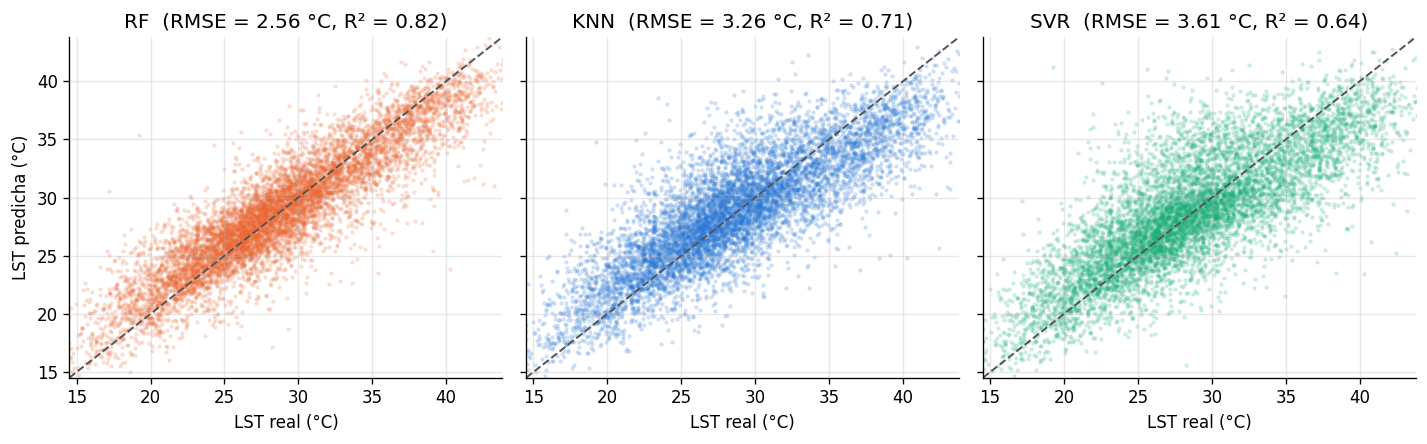

In [17]:
fig, axes = plt.subplots(1, len(predicciones), figsize=(4 * len(predicciones), 3.8), sharex=True, sharey=True)
lim = [np.percentile(y_pru, 0.5), np.percentile(y_pru, 99.5)]
for ax, (nombre, pred) in zip(np.atleast_1d(axes), predicciones.items()):
    r = resultados_prueba.set_index("modelo").loc[nombre]
    ax.scatter(y_pru, pred, s=3, alpha=0.15, color=COLORES[nombre])
    ax.plot(lim, lim, ls="--", color="#555555", lw=1.2)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{nombre}  (RMSE = {r['RMSE']:.2f} °C, R² = {r['R2']:.2f})")
    ax.set_xlabel("LST real (°C)")
np.atleast_1d(axes)[0].set_ylabel("LST predicha (°C)")
fig.tight_layout()
fig.savefig("figuras/real_vs_predicho.png", dpi=200)
plt.show()

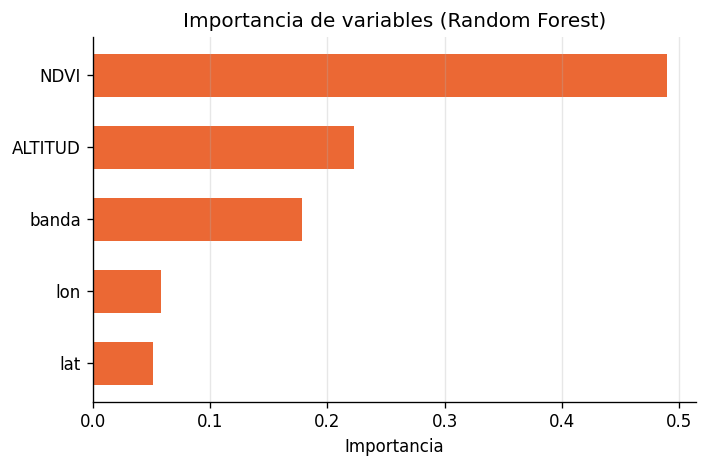

In [18]:
# Qué variables usa más el Random Forest para predecir la temperatura
if "RF" in modelos_finales:
    imp = pd.Series(modelos_finales["RF"].feature_importances_, index=par.COLUMNAS_X).sort_values()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(imp.index, imp.values, color="#eb6834", height=0.6)
    ax.set_xlabel("Importancia")
    ax.set_title("Importancia de variables (Random Forest)")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig("figuras/importancia_variables.png", dpi=200)
    plt.show()
    imp.sort_values(ascending=False).round(3).to_csv("resultados/importancia_variables.csv")

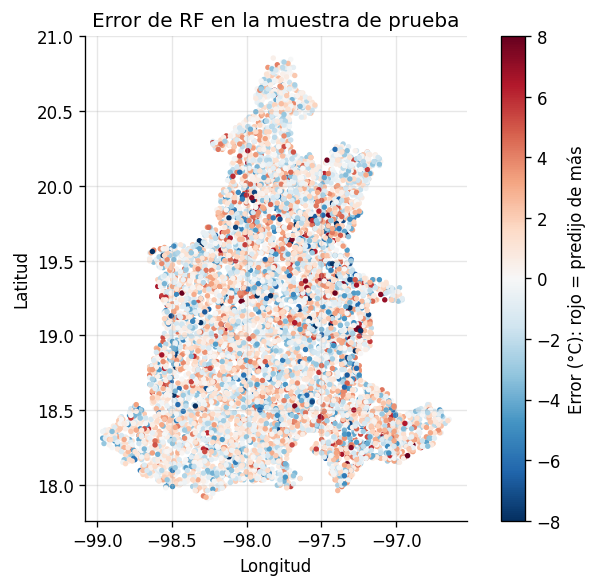

In [19]:
# Mapa del error del mejor modelo en la muestra de prueba (dónde se equivoca más)
mejor = resultados_prueba.iloc[0]["modelo"]
error = predicciones[mejor] - y_pru
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(prueba["lon"], prueba["lat"], c=error, s=5, cmap="RdBu_r", vmin=-8, vmax=8)
fig.colorbar(sc, ax=ax, label="Error (°C): rojo = predijo de más")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Error de {mejor} en la muestra de prueba")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig("figuras/mapa_error.png", dpi=200)
plt.show()

## 9. Archivos generados

- `resultados/resumen_datos.csv` y `resultados/descripcion_variables.csv`: descripción de la muestra.
- `resultados/curvas_aprendizaje.csv` y `figuras/curvas_aprendizaje.png`: curvas de aprendizaje.
- `resultados/busqueda_hiperparametros.csv`: combinaciones con RMSE, MAE, R² y tiempo.
- `resultados/desempeno_paralelo.csv`: tiempo, speedup, eficiencia y Karp-Flatt por número de procesos.
- `resultados/estatico_vs_dinamico.csv`: comparación de los dos repartos.
- `resultados/resultados_prueba.csv`: métricas finales en la muestra de prueba.
- `resultados/importancia_variables.csv` y `figuras/importancia_variables.png`: importancia de variables del Random Forest.
- `figuras/*.png`: figuras para el documento (200 dpi).